In [ ]:
# Run from the repo root so relative paths (combined/, data/, results/) work,
# no matter which folder Jupyter started this notebook in.
import os
from pathlib import Path
_here = Path.cwd().resolve()
os.chdir(next(p for p in [_here, *_here.parents] if (p / "pyproject.toml").exists()))
print("working directory:", Path.cwd())

# Phase 3 — Fixed model setup and validation

**Study:** Stack Overflow Developer Survey, 2011–2026 · annual salary regression  
**Input:** `combined/all_years_fixed.csv` · **Target:** `Comp_USD_Annual`  
**Output (in memory only):** `df` (unaltered loaded data), `X`, `y`, `salary_outlier_flag`, `region_metadata`  
**Boundary:** This notebook **does not** split the data, fit a transformer, scale values, estimate imputation statistics, or train a model.

Run in order using **Kernel → Restart & Run All**. Run from the project root, where `combined/all_years_fixed.csv` exists. No CSVs or other files are written by this notebook.

### The Phase 3 contract
1. Load the exported 33-column survey dataset while preserving literal answers such as `None` and `NA`.
2. Validate salary and define `y = ln(Comp_USD_Annual)`; do **not** silently filter respondents again.
3. Select only approved model inputs, excluding salary leakage, IDs, target-derived flags, and downstream outcomes.
4. Label missing *categorical* responses as **Not asked** or **No answer** according to a fixed survey-year rule.
5. Keep `survey_year` numeric and keep missing *numeric* values for **training-only** handling in later phases.
6. Run explicit assertions for model schema, missingness, target validity, and `X`/`y` alignment.

## 1. Load source data and verify schema

The import settings are intentional: `keep_default_na=False, na_values=[""]` converts **only blank fields** to missing values. Text answers such as `None` and `NA` remain literal categories. We keep the imported table named `df` unchanged for traceability.

The size from the previous run is shown as a **provenance warning** rather than a hard constraint, because a freshly regenerated CSV may have a legitimate different row count.

In [94]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

DATA_PATH = Path("combined/all_years_fixed.csv")
TARGET = "Comp_USD_Annual"
MIN_SALARY, MAX_SALARY = 1_000, 1_000_000

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Missing input: {DATA_PATH.resolve()}. "
        "Launch the notebook from your project root and verify the cleaning export."
    )

df = pd.read_csv(
    DATA_PATH,
    keep_default_na=False,
    na_values=[""],
    low_memory=False,
)

EXPECTED_INPUTS = {
    TARGET, "survey_year", "Country", "Country_grouped", "Region",
    "comp_outlier_country", "Age", "YearsCode", "YearsCodePro", "WorkExp",
    "OrgSize", "EdLevel", "Employment", "Industry", "RemoteWork",
    "LearnCode", "OpSys", "MainBranch", "DevType",
    "LanguageHaveWorkedWith", "LanguageWantToWorkWith",
    "LanguageHaveWorkedWith_count", "PurchaseInfluence",
}
missing_columns = sorted(EXPECTED_INPUTS - set(df.columns))
if missing_columns:
    raise KeyError(f"Export is missing expected fields: {missing_columns}")
if not df.columns.is_unique or not df.index.is_unique:
    raise ValueError("Duplicate columns or row index in exported dataset.")

source_year = pd.to_numeric(df["survey_year"], errors="raise")
if source_year.isna().any() or not (source_year % 1 == 0).all():
    raise ValueError("survey_year must contain integer years without missing values.")
# Do not rewrite the loaded df: type conversion is done in the X copy below.

print("=== SOURCE EXPORT ===")
#print("Path:", DATA_PATH.resolve())
print("Rows / columns:", df.shape)
print("Years:", sorted(df["survey_year"].unique().tolist()))
if df.shape != (386_701, 33):
    print("PROVENANCE NOTE: Previous execution used (386701, 33); inspect changes in the cleaning export.")

=== SOURCE EXPORT ===
Rows / columns: (386701, 33)
Years: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


## 2. Validate and log-transform salary

The target is **annual nominal USD** as defined by the *selected v2 cleaning export*, **not** necessarily the separately audited compensation pipeline. The source file already uses the agreed $1,000–$1,000,000 window; Phase 3 only verifies it.

With a log target, a coefficient for a one-unit change in a numeric predictor has exact percentage effect `100 × (exp(β) − 1)%` under the specified linear model, holding other variables fixed. For small coefficients, `100 × β%` is an approximation. This is **association**, not automatically causation.

In [95]:
salary: pd.Series = df[TARGET].astype("float64")
if salary.isna().any() or not np.isfinite(salary.to_numpy()).all():
    raise ValueError("Target salary contains missing, infinite or non-finite values.")
if not salary.between(MIN_SALARY, MAX_SALARY).all():
    raise ValueError(
        f"Salary outside the declared ${MIN_SALARY:,}–${MAX_SALARY:,} window. "
        "Do not filter silently here; review the cleaning export."
    )

y: pd.Series = pd.Series(
    np.log(salary.to_numpy(dtype=float)),
    index=salary.index,
    name="log_annual_salary_usd"
)

print("=== TARGET ===")
print("Observations:", len(y))
print("Raw annual USD range:", salary.min(), "to", salary.max())
display(y.describe().to_frame())

=== TARGET ===
Observations: 386701
Raw annual USD range: 1000.0 to 1000000.0


,log_annual_salary_usd
count,386701.000000
mean,10.875020
std,1.048681
min,6.907755
25%,10.355073
50%,11.047296
75%,11.548949
max,13.815511


## 3. Keep sensitivity metadata **outside** the predictor matrix

- `comp_outlier_country` is **derived from compensation** and is not a legitimate standard predictor. We retain it only for the preplanned Phase 9 sensitivity analysis.
- `Region` is fixed geographic metadata for later train-only country pooling; it is not an additional model input.
- `Country_grouped` from the exported CSV was calculated using **full-dataset country counts**. We *do not use it* in the primary predictor matrix. The grouping threshold must be learned from training data after the split.

The salary outlier flag was also calculated using the full dataset. Keep it out of `X`; any later sensitivity analysis based on that label-derived flag should explicitly document how it defines the evaluation sample.

In [96]:
salary_outlier_flag = df["comp_outlier_country"].copy()
region_metadata = df["Region"].copy()

assert salary_outlier_flag.index.equals(y.index)
assert region_metadata.index.equals(y.index)

print("=== SENSITIVITY METADATA (NOT PREDICTORS) ===")
display(salary_outlier_flag.value_counts(dropna=False).rename_axis("Flag").to_frame("Rows"))

=== SENSITIVITY METADATA (NOT PREDICTORS) ===


,Rows
Flag,
0,378062
1,8639


## 4. Select exactly the approved 18 predictors

Drop the DROP_FOR_MODEL columns, then check that exactly 18 predictors remain; if a new export adds an unexpected column, the notebook stops.

Numeric (6)	
survey_year, Age, YearsCode, YearsCodePro, WorkExp, OrgSize	

Categorical (12)
Country_grouped, EdLevel, Employment, Industry, RemoteWork, LearnCode, OpSys, MainBranch, PurchaseInfluence, DevType, LanguageHaveWorkedWith, LanguageWantToWorkWith

In [97]:
DROP_FOR_MODEL = ["Comp_USD_Annual", "CompTotal", "ConvertedCompYearly", "comp_outlier_country",
                  "Currency", "Currency_ISO", "CompFreq", "comp_source", "uid", "ResponseId",
                  "Country", "Region", "JobSat", "CompIsTotalComp"]


NUMERIC = ["survey_year", "Age", "YearsCode", "YearsCodePro", "WorkExp", "OrgSize", "LanguageHaveWorkedWith_count"]

NOT_ASKED = {
    "EdLevel": list(range(2011, 2017)),
    "Employment": list(range(2011, 2015)),
    "Industry": list(range(2017, 2023)),
    "RemoteWork": [2011, 2012, 2013, 2018, 2020, 2021],
    "LearnCode": [2011, 2012, 2013, 2014, 2020],
    "OpSys": [2017, 2026],
    "MainBranch": list(range(2011, 2017)) + [2018, 2026],
    "LanguageWantToWorkWith": [2011, 2012, 2013],
    "PurchaseInfluence": [2016, 2018, 2021],
}
ALWAYS_ASKED = ["DevType", "LanguageHaveWorkedWith", "Country_grouped"]
CATEGORICAL = list(NOT_ASKED) + ALWAYS_ASKED
FEATURES = NUMERIC + CATEGORICAL

assert len(NUMERIC) == 7 and len(CATEGORICAL) == 12
assert len(FEATURES) == 19 and len(set(FEATURES)) == 19
missing_features = sorted(set(FEATURES) - set(df.columns))
if missing_features:
    raise KeyError(f"Expected modeling predictors absent from source CSV: {missing_features}")

# Drop excluded columns, then check exactly the 18 intended predictors remain
X = df.drop(columns=[c for c in DROP_FOR_MODEL if c in df.columns]).copy()
extra = sorted(set(X.columns) - set(FEATURES))
missing = sorted(set(FEATURES) - set(X.columns))
if extra or missing:
    raise ValueError(
        f"Input schema differs from 18-predictor design. Extra: {extra}; missing: {missing}. "
        "Review the export and update the specification deliberately."
    )
X = X.loc[:, FEATURES]  # stable feature order, leaves df and CSV untouched

print("=== FEATURE SELECTION ===")
print("X:", X.shape, "| y:", y.shape)
print("Excluded CSV columns:", sorted(set(df.columns) - set(FEATURES)))

=== FEATURE SELECTION ===
X: (386701, 19) | y: (386701,)
Excluded CSV columns: ['CompFreq', 'CompIsTotalComp', 'CompTotal', 'Comp_USD_Annual', 'ConvertedCompYearly', 'Country', 'Currency', 'Currency_ISO', 'JobSat', 'Region', 'ResponseId', 'comp_outlier_country', 'comp_source', 'uid']


## 5. Verify numeric data — do not impute

Cast numeric features using `errors="raise"` so unexpected text is surfaced rather than turned into missing values. Leave all numeric nulls intact. In particular, `WorkExp` was **not asked before 2022**, and `YearsCodePro` is structurally absent in several years; their large missing counts must not be interpreted as ordinary skipped responses.

In [98]:
X["survey_year"] = pd.to_numeric(X["survey_year"], errors="raise").astype("int64")
for col in NUMERIC:
    if col != "survey_year":
        X[col] = pd.to_numeric(X[col], errors="raise")

numeric_missing_before = df[NUMERIC].isna().sum().astype(int)
numeric_missing_after = X[NUMERIC].isna().sum().astype(int)
assert numeric_missing_before.equals(numeric_missing_after), "Numeric missingness unexpectedly changed."

print("=== NUMERIC NULLS PRESERVED ===")
display(numeric_missing_after.rename("Missing").to_frame())

=== NUMERIC NULLS PRESERVED ===


,Missing
survey_year,0
Age,21590
YearsCode,1220
YearsCodePro,100098
WorkExp,280225
OrgSize,30075
LanguageHaveWorkedWith_count,9964


## 7. Label missing categorical answers with **fixed** year rules

- **Not asked:** The question was unavailable in that survey year and the corresponding exported value is blank.
- **No answer:** The question existed that year but this respondent's value is blank.
- **Literal responses** such as `None`, `NA`, or an actual respondent answer are not replaced.
This includes PurchaseInfluence (2016, 2018, 2021 not asked) as specified. Country_grouped is assumed available every year and receives No answer for missing values.

The labels are fixed year rules; no training-set values are learned. Later, one-hot/multi-hot encoding must be fitted on training data only.

In [99]:
# ============================================
# CATEGORICAL MISSINGNESS
# ============================================

for col in CATEGORICAL:
    values = X[col].astype("string").str.strip().replace("", pd.NA)

    if col in NOT_ASKED:
        missing_not_asked = (
            values.isna()
            & X["survey_year"].isin(NOT_ASKED[col])
        )
        values = values.mask(missing_not_asked, "Not asked")

    X[col] = values.fillna("No answer")

missingness_summary = pd.DataFrame({
    "Not asked": [int(X[c].eq("Not asked").sum()) for c in CATEGORICAL],
    "No answer": [int(X[c].eq("No answer").sum()) for c in CATEGORICAL],
    "Remaining null": [int(X[c].isna().sum()) for c in CATEGORICAL],
}, index=CATEGORICAL)

print("=== CATEGORICAL MISSINGNESS ===")
display(missingness_summary)

print("\n=== FINAL ORGANIZATION SIZE DISTRIBUTION ===")
display(X["OrgSize"].value_counts(dropna=False).to_frame("Rows"))

=== CATEGORICAL MISSINGNESS ===


,Not asked,No answer,Remaining null
EdLevel,65070,1870,0
Employment,14915,1375,0
Industry,219316,29108,0
RemoteWork,130531,7246,0
LearnCode,48911,23044,0
OpSys,24730,13587,0
MainBranch,118788,0,0
LanguageWantToWorkWith,10535,33686,0
PurchaseInfluence,122663,14608,0
DevType,0,2696,0



=== FINAL ORGANIZATION SIZE DISTRIBUTION ===


,Rows
OrgSize,
10.0,80575
60.0,78942
300.0,69136
15000.0,49623
3000.0,39839
NaN,30075
750.0,23778
7500.0,14733


## 8. Acceptance checks — all must pass

These assertions test the **actual Phase 3 contract**, not simply the absence of exceptions. They check target integrity, row/index alignment, categorical labeling rules for blank values, numeric preservation, known leakage fields, expected column roles, and retained sensitivity metadata.

In [100]:
# Target / row alignment
assert len(X) == len(y) == len(df)
assert X.index.equals(y.index) and X.columns.is_unique
assert np.isfinite(y.to_numpy()).all()
np.testing.assert_allclose(y.to_numpy(), np.log(salary.to_numpy()), rtol=0, atol=1e-12)
assert salary.between(MIN_SALARY, MAX_SALARY).all()

# Exact schema and data types
assert set(X.columns) == set(FEATURES) == set(NUMERIC + CATEGORICAL)
assert len(NUMERIC) == 7 and len(CATEGORICAL) == 12 and len(FEATURES) == 19
assert pd.api.types.is_integer_dtype(X["survey_year"])
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in NUMERIC)
assert "OrgSize" in NUMERIC and "OrgSize" not in CATEGORICAL
assert pd.api.types.is_numeric_dtype(X["OrgSize"])
assert X[CATEGORICAL].notna().all().all()
assert X[NUMERIC].isna().sum().astype(int).equals(numeric_missing_before)

assert not (set(X.columns) & set(DROP_FOR_MODEL))
assert not any(c.startswith("PurchaseInfluence__") for c in X.columns)
assert "Country_grouped" in X.columns and "Country" not in X.columns
assert "PurchaseInfluence" in X.columns
assert "LanguageHaveWorkedWith_count" in X.columns
assert pd.api.types.is_numeric_dtype(X["LanguageHaveWorkedWith_count"])
assert "WorkExp" in X.columns
assert "comp_outlier_country" in df.columns
assert salary_outlier_flag.index.equals(y.index)
assert region_metadata.index.equals(y.index)

# Every blank raw categorical response receives the appropriate fixed label.
for col in CATEGORICAL:
    raw = df[col].astype("string").str.strip()
    missing_raw = raw.isna() | raw.eq("").fillna(False)
    not_asked_year = source_year.isin(NOT_ASKED.get(col, []))
    expected_not_asked = missing_raw & not_asked_year
    expected_no_answer = missing_raw & ~not_asked_year
    assert X.loc[expected_not_asked, col].eq("Not asked").all(), col
    assert X.loc[expected_no_answer, col].eq("No answer").all(), col

print("PHASE 3: ALL ACCEPTANCE CHECKS PASSED")
print(f"Rows: {len(X):,} | predictors: {len(FEATURES)} ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print("Target: log annual USD salary | survey_year dtype:", X["survey_year"].dtype)

PHASE 3: ALL ACCEPTANCE CHECKS PASSED
Rows: 386,701 | predictors: 19 (7 numeric, 12 categorical)
Target: log annual USD salary | survey_year dtype: int64


## 9. Handoff summary for Phase 4 (inspection only)

Here we print the per-year sample sizes and missing numeric counts. No preprocessing is fitted. This is especially important for `WorkExp` and `YearsCodePro`, whose absence is partly **structural**. Keep survey-year stratification, missingness indicators, or feature-subset comparisons in mind when designing the **training-only** imputation strategy.

In [101]:
print("=== MODELING ROWS BY SURVEY YEAR ===")
display(X.groupby("survey_year").size().rename("Respondents").to_frame())

print("=== NUMERIC MISSINGNESS BY YEAR (PERCENT) ===")
display((X[NUMERIC].isna().groupby(X["survey_year"]).mean() * 100).round(1))

print("=== READY FOR SPLIT ===")
print("X:", X.shape, "y:", y.shape)
print("Outlier flag:", salary_outlier_flag.shape, "region metadata:", region_metadata.shape)

=== MODELING ROWS BY SURVEY YEAR ===


,Respondents
survey_year,
2011,2031
2012,3466
2013,5038
2014,4380
2015,13492
2016,36663
2017,12573
2018,41561
2019,50402


=== NUMERIC MISSINGNESS BY YEAR (PERCENT) ===


,survey_year,Age,YearsCode,YearsCodePro,WorkExp,OrgSize,LanguageHaveWorkedWith_count
survey_year,,,,,,,
2011,0.0,0.0,0.0,100.0,100.0,0.0,0.6
2012,0.0,0.0,0.0,100.0,100.0,0.0,0.5
2013,0.0,0.0,0.0,100.0,100.0,0.0,0.4
2014,0.0,0.0,0.0,100.0,100.0,100.0,6.1
2015,0.0,0.6,0.1,100.0,100.0,100.0,1.6
2016,0.0,0.4,0.4,100.0,100.0,6.2,2.2
2017,0.0,100.0,0.1,0.4,100.0,1.7,5.7
2018,0.0,5.6,0.0,0.3,100.0,9.7,2.3
2019,0.0,4.2,0.2,0.3,100.0,1.6,0.4


=== READY FOR SPLIT ===
X: (386701, 19) y: (386701,)
Outlier flag: (386701,) region metadata: (386701,)


## 10. Known upstream limitations and next-phase rules

**Passed Phase 3 ≠ validated raw survey harmonization.** The following issues cannot be fully repaired from the 33-column export and should be addressed in the cleaning source before treating related coefficients as final:

1. **Organization-size misclassification:** Some very broad original sizes (e.g., `Fortune 1000 (1,000+)`, `3001+`) were assigned to narrow bins in the v2 cleaning pipeline. This notebook correctly keeps the bin codes as numbers (log-scaled in Phase 6).
2. **Historical ages:** Some range-to-bracket approximations in v2 do not preserve the original age interval exactly. Original response data is needed for corrected ages.
3. **Employment and remote work:** Generic `Employed` responses and occasionally-remote categories were mapped to more specific values upstream. The exact original categories are no longer available in this export.
4. **Salary and population provenance:** The v2 export favors published `ConvertedCompYearly` and applies its own respondent exclusions. It is **not** interchangeable with the separately audited salary-cleaning version.
5. **Country-year salary outlier flag:** Computed from salary and the full exported dataset. It is preserved for sensitivity work but excluded from predictors. Do not use it to choose features or train/test preprocessing.

**Phase 4+ requirements:** Split respondents first; fit country-count pooling on *training only* and apply the learned mapping to test; impute and scale numeric fields using training data; multi-hot encode semicolon-delimited fields instead of treating combinations as categories; explicitly route `survey_year` through the numeric transformer; make any salary-based sensitivity analysis a documented separate evaluation.

**Reproducibility step:** Run **Kernel → Restart & Run All**, then **Save** the notebook. If the export is unchanged, the counts should match the reference results above. If they differ, inspect the cleaning notebook's provenance rather than forcibly adjusting the data to make the numbers match.

In [102]:
cols = ["OrgSize", "Country_grouped", "PurchaseInfluence"]

print("In df:")
print(df[cols].dtypes)

print("\nIn X:")
print(X[cols].dtypes)

print("\nMissing values in X:")
print(X[cols].isna().sum())

In df:
OrgSize              float64
Country_grouped          str
PurchaseInfluence        str
dtype: object

In X:
OrgSize              float64
Country_grouped       string
PurchaseInfluence     string
dtype: object

Missing values in X:
OrgSize              30075
Country_grouped          0
PurchaseInfluence        0
dtype: int64


# Phase 4 - Splitting the Dataset (Train/Validation/Test)

One switch (`RUN`) picks how the data is split. Both runs produce the same six variables (`X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`), so every later phase uses identical code.

**Run A (main):** split by year. Train on 2011–2024, choose settings on 2025 (validation), and test once on 2026. This measures how well the model predicts a year it has never seen.
  
**Run B (baseline):** random 70/15/15 split across all years. `stratify` keeps each year's share equal in all three sets (2011 has about 2,000 respondents, 2016 about 37,000), and `random_state=42` gives every teammate the same split. The second split takes 0.15 / 0.85 of the remaining 85%, which is 15% of the whole.

## 1. The Split (A & B)
Run A first through both steps (1-2), and then proceed to change and run B.

In [103]:
from sklearn.model_selection import train_test_split

RUN = "A"   # "A" = by year (main result), "B" = random 70/15/15 (baseline)

if RUN == "A":
    tr = X["survey_year"] <= 2024
    va = X["survey_year"] == 2025
    te = X["survey_year"] == 2026
    X_train, X_val, X_test = X[tr].copy(), X[va].copy(), X[te].copy()
    y_train, y_val, y_test = y[tr], y[va], y[te]
else:
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=0.15, random_state=42, stratify=X["survey_year"])
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=0.15 / 0.85, random_state=42, stratify=X_tmp["survey_year"])

print(len(X_train), len(X_val), len(X_test))

352925 21619 12157


## 2. Checking Split
Confirms that `X` and `y` rows line up, that no rows were lost or duplicated, and that train, validation and test don't overlap. Then prints each set's size and the years it covers.

Expected: 

**Run A** is with training covering 2011–2024, validation only 2025, and test only 2026. 

**Run B** is about 70% / 15% / 15%, with every set spanning 2011–2026.

In [104]:
assert X.index.equals(y.index), "X and y rows don't line up"
# Check row alignment
assert X.index.equals(y.index), "X and y rows don't line up"

assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

# Check no rows were lost or duplicated
assert len(X_train) + len(X_val) + len(X_test) == len(X), "rows lost or duplicated"

# Check all three splits are mutually exclusive
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

# Check all original rows are represented
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(X.index)

assert X.index.is_unique, "Original respondent index contains duplicates"

# Check all 19 predictors are preserved
assert X_train.shape[1] == 19
assert X_val.shape[1] == 19
assert X_test.shape[1] == 19

assert X_train.columns.equals(X.columns)
assert X_val.columns.equals(X.columns)
assert X_test.columns.equals(X.columns)

# Check chronological year boundaries for Run A
if RUN == "A":
    assert X_train["survey_year"].le(2024).all()
    assert X_val["survey_year"].eq(2025).all()
    assert X_test["survey_year"].eq(2026).all()


print(f"=== PHASE 4 VALIDATION PASSED ===")
print(f"RUN = {RUN}")
for name, part in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{name:5s} {len(part):>7,} ({len(part)/len(X):.1%})  years {part['survey_year'].min()}–{part['survey_year'].max()}")

print(f"Predictors: {X_train.shape[1]}")


=== PHASE 4 VALIDATION PASSED ===
RUN = A
train 352,925 (91.3%)  years 2011–2024
val    21,619 (5.6%)  years 2025–2025
test   12,157 (3.1%)  years 2026–2026
Predictors: 19


## Phase 4 Results
| | Run A (by year) | Run B (random, stratified) |
|---|---|---|
| Train | 352,925 (91.3%), 2011–2024 | 270,689 (70.0%), 2011–2026 |
| Validation | 21,619 (5.6%), 2025 | 58,006 (15.0%), 2011–2026 |
| Test | 12,157 (3.1%), 2026 | 58,006 (15.0%), 2011–2026 |

All split checks passed: X and y rows align, no rows were lost or duplicated, and the sets don't overlap. The notebook is left on `RUN = "A"` for Phases 5–9.

## Short Report

We evaluate the models under two data splits. In Run A, the main setting, we train on the 2011–2024 surveys (352,925 respondents), tune on 2025 (21,619) and test once on 2026 (12,157). This measures how well a model predicts salaries in a survey year it has never seen. In Run B, the baseline, we randomly split all years 70/15/15, keeping each year’s share equal across the three sets. This measures how well a model predicts new respondents from years it already knows. We expect Run B to score higher, since it sees every year’s salary levels and survey format during training; the gap between the two runs shows the cost of predicting a new year. Run A’s test set is small (3.1% of respondents) because it contains only one survey year.

## 3. How to Switch Runs (Informational Only)
Run Phases 4–9 with `RUN = "A"` and save the results, then set `RUN = "B"` and re-run from this phase down. Phase 3 doesn't need to be re-run, since the split doesn't change `X` or `y`.

In the report, both results are shown: Run A measures performance on a future year, and Run B on years the model has already seen. The gap between them is the cost of predicting a new year.

## Phase 5 - Impute NUMBER COLUMNS missing whole years (fit on training only)

-Define and fit the imputers


In [105]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# ============================================
# 1. AGE DONOR IMPUTATION
# ============================================
'''
Builds per-YearsCode-bucket pools of observed ages from 2016/2018 training rows, raising if none exist.
'''
def fit_age_donors(train):
    mask = (
        train["survey_year"].isin([2016, 2018])
        & train[["Age", "YearsCode"]].notna().all(axis=1)
    )

    donors = train.loc[mask, ["YearsCode", "Age"]]

    if donors.empty:
        raise ValueError("No eligible training-only age donors.")

    return {
        code: group["Age"].to_numpy(dtype=float)
        for code, group in donors.groupby(donors["YearsCode"].round())
    }

'''
Draws donor ages with replacement into missing 2017 Age values and adds an Age_imputed flag.
'''
def impute_age(data, pools, rng):
    out = data.copy()

    original_missing = out["Age"].isna()
    out["Age_imputed"] = original_missing.astype("int8")

    mask = (
        original_missing
        & out["survey_year"].eq(2017)
        & out["YearsCode"].notna()
    )

    # Available YearsCode groups from training-only donors
    donor_keys = np.array(sorted(pools.keys()), dtype=float)

    if len(donor_keys) == 0:
        raise ValueError("No age donor groups available.")

    groups = out.loc[mask].groupby(
        out.loc[mask, "YearsCode"].round()
    ).groups

    for code, indices in groups.items():

        # First preference: exact rounded match
        if code in pools:
            candidates = pools[code]

        else:
            # Fallback: nearby experience groups (within 2 years)
            nearby = donor_keys[
                np.abs(donor_keys - float(code)) <= 2
            ]

            if len(nearby) == 0:
                continue

            candidates = np.concatenate([
                pools[key] for key in nearby
            ])

        # Sample actual observed ages
        out.loc[indices, "Age"] = rng.choice(
            candidates,
            size=len(indices),
            replace=True
        )

    return out

# ============================================
# 2. YEARSCODEPRO REGRESSION IMPUTATION
# ============================================

'''
Fits three cascading LinearRegression models (recent, early, backup) on progressively wider year windows and shrinking feature sets.
'''
def fit_ycp(train):
    specs = {
        "recent": (
            ["WorkExp", "YearsCode", "Age"],
            train["survey_year"].between(2022, 2024)
        ),
        "early": (
            ["YearsCode", "Age"],
            train["survey_year"].between(2018, 2024)
        ),
        "backup": (
            ["YearsCode"],
            train["survey_year"].between(2017, 2024)
        )
    }

    fitted: dict[str, tuple[list[str], LinearRegression]] = {}

    for name, (cols, year_mask) in specs.items():

        rows = train.loc[year_mask].dropna(
            subset=cols + ["YearsCodePro"]
        )

        if len(rows) <= len(cols) + 10:
            raise ValueError(
                f"{name}: insufficient complete training rows "
                f"({len(rows)})"
            )

        model = LinearRegression().fit(
            rows[cols],
            rows["YearsCodePro"]
        )

        fitted[name] = (cols, model)

        print(
            f"{name}: {len(rows):,} training rows | "
            f"predictors: {cols}"
        )

    return fitted

'''
Predicts missing professional-experience values for pre-2017 and 2025–2026 rows, clipping output to [0, YearsCode].
'''

def impute_ycp(
    data: pd.DataFrame,
    models: dict[str, tuple[list[str], LinearRegression]]
) -> pd.DataFrame:
    out = data.copy()

    # Flag original missingness, including Phase 6 fallbacks
    original_missing = out["YearsCodePro"].isna()
    out["YearsCodePro_imputed"] = original_missing.astype("int8")

    year = out["survey_year"]

    target_years = (
        year.le(2016)
        | year.isin([2025, 2026])
    )

    steps = [
        ("recent", year.isin([2025, 2026])),
        ("early", year.le(2016)),
        ("backup", target_years)
    ]

    for name, eligible in steps:
        cols, model = models[name]

        mask = (
            out["YearsCodePro"].isna()
            & eligible
            & out[cols].notna().all(axis=1)
        )

        if not mask.any():
            continue

        predictions = model.predict(out.loc[mask, cols])

        max_years = out.loc[
            mask, "YearsCode"
        ].to_numpy(dtype=float)

        out.loc[mask, "YearsCodePro"] = np.clip(
            predictions,
            0,
            max_years
        )

    return out

## Fit and transform

This executes the end-to-end imputation workflow for Phase 5. It validates the run configuration and input schema, fits donor pools and regression models exclusively on the training split, applies the fitted rules to all three splits (train, val, test) in a single deterministic pass, and updates the feature schema to include imputation flag columns while dropping the original WorkExp predictor.

### Execution Logic
- Assertions - Confirms RUN is "A" or "B", that `X_train` has exactly 19 columns, and that "WorkExp" is present.
- Audit baseline - Records missing-value counts for `Age, YearsCodePro, and OrgSize` across all three splits before any imputation occurs.
- Fit on training data only - Calls `fit_age_donors(X_train)` and `fit_ycp(X_train)` to build reusable imputation artifacts.
T- ransform all splits - Applies `impute_age` then `impute_ycp` to each split using a fixed `np.random.default_rng(42)` for reproducibility, then drops the WorkExp column.
- Schema update - Removes `WorkExp` from NUMERIC, appends `Age_imputed` and `YearsCodePro_imputed`, and recomputes the FEATURES list.
- Logging - Prints a summary header confirming the run identifier and final predictor counts.

In [106]:
# ============================================
# PHASE 5 — FIT AND TRANSFORM
# ============================================

assert RUN in {"A", "B"}
assert X_train.shape[1] == 19
assert "WorkExp" in X_train.columns

# Capture missingness BEFORE imputation for auditing
tracked = ["Age", "YearsCodePro", "OrgSize"]

missing_before = {
    name: part[tracked].isna().sum()
    for name, part in [("train", X_train), ("val", X_val), ("test", X_test)]}

# FIT ON TRAINING DATA ONLY
age_pools = fit_age_donors(X_train)
ycp_models = fit_ycp(X_train)

# Fixed seed for reproducible age sampling
rng = np.random.default_rng(42)

# TRANSFORM — same fitted rules for all three splits
X_train, X_val, X_test = [
    impute_ycp(
        impute_age(part, age_pools, rng),
        ycp_models
    ).drop(columns="WorkExp")
    for part in (X_train, X_val, X_test)
]

# Update schema for Phase 6
NUMERIC = [
    c for c in NUMERIC
    if c != "WorkExp"
] + [
    "Age_imputed",
    "YearsCodePro_imputed"
]

FEATURES = NUMERIC + CATEGORICAL

print("=== PHASE 5 IMPUTATION APPLIED ===")
print("Run:", RUN)
print("Numeric predictors:", len(NUMERIC))
print("Categorical predictors:", len(CATEGORICAL))
print("Total predictors:", len(FEATURES))

recent: 72,601 training rows | predictors: ['WorkExp', 'YearsCode', 'Age']
early: 265,156 training rows | predictors: ['YearsCode', 'Age']
backup: 286,300 training rows | predictors: ['YearsCode']
=== PHASE 5 IMPUTATION APPLIED ===
Run: A
Numeric predictors: 8
Categorical predictors: 12
Total predictors: 20


### Validation

This script verifies that the imputation pipeline produced structurally correct, leakage-free outputs across all three splits. It asserts schema consistency, confirms that imputation only reduced (never increased) missingness in tracked columns, ensures `OrgSize` was left untouched for Phase 6, and prints audit tables summarizing remaining gaps and original-missingness flags before declaring Phase 5 complete.

In [107]:
# ============================================
# PHASE 5 — VALIDATION
# ============================================

assert len(NUMERIC) == 8
assert len(CATEGORICAL) == 12
assert len(FEATURES) == 20

parts = {
    "train": (X_train, y_train),
    "val": (X_val, y_val),
    "test": (X_test, y_test)
}

for name, (part, target) in parts.items():

    # Alignment and feature schema
    assert part.index.equals(target.index), name
    assert set(part.columns) == set(FEATURES), name
    assert part.shape[1] == 20, name

    # WorkExp was deliberately removed
    assert "WorkExp" not in part.columns, name

    # Flags contain only 0 and 1
    assert part["Age_imputed"].isin([0, 1]).all(), name
    assert part["YearsCodePro_imputed"].isin([0, 1]).all(), name

    # Imputation must not introduce additional missing values
    for col in tracked:
        assert (
            part[col].isna().sum()
            <= missing_before[name][col]
        ), (name, col)

    # OrgSize remains untouched until Phase 6
    assert (
        part["OrgSize"].isna().sum()
        == missing_before[name]["OrgSize"]
    ), name

# Audit remaining missingness
remaining_missing = pd.DataFrame({
    name: part[tracked].isna().sum()
    for name, (part, _) in parts.items()
}).T

print("=== REMAINING MISSING VALUES ===")
display(remaining_missing)

# Audit original missingness flags
flag_summary = pd.DataFrame({
    name: part[
        ["Age_imputed", "YearsCodePro_imputed"]
    ].sum()
    for name, (part, _) in parts.items()
}).T

print("\n=== ORIGINALLY MISSING VALUES ===")
display(flag_summary)

print("\n=== FINAL PHASE 5 SHAPES ===")
for name, (part, _) in parts.items():
    print(f"{name}: {part.shape}")

print("\nPHASE 5 VALIDATION PASSED")

=== REMAINING MISSING VALUES ===


,Age,YearsCodePro,OrgSize
train,8992,1434,27835
val,15,121,2037
test,21,169,203



=== ORIGINALLY MISSING VALUES ===


,Age_imputed,YearsCodePro_imputed
train,21554,66322
val,15,21619
test,21,12157



=== FINAL PHASE 5 SHAPES ===
train: (352925, 20)
val: (21619, 20)
test: (12157, 20)

PHASE 5 VALIDATION PASSED


#### Remaining Missingness by Year
This script audits the imputation results by breaking down missing-value counts and originally-missing flags per `survey_year` for each split `(train, val, test)`. It reports the number of respondents, remaining gaps in `Age/YearsCodePro/OrgSize`, and the total count of imputed rows per year to confirm whether imputation coverage varies by survey year and to identify any remaining gaps for downstream handling.

In [108]:
# ============================================
# PHASE 5 — REMAINING MISSINGNESS BY YEAR
# ============================================

for name, part in [
    ("train", X_train),
    ("val", X_val),
    ("test", X_test)
]:
    print(f"\n=== {name.upper()} ===")

    audit = part.groupby("survey_year").agg(
        respondents=("survey_year", "size"),
        age_missing=("Age", lambda s: s.isna().sum()),
        ycp_missing=("YearsCodePro", lambda s: s.isna().sum()),
        orgsize_missing=("OrgSize", lambda s: s.isna().sum()),
        age_originally_missing=("Age_imputed", "sum"),
        ycp_originally_missing=("YearsCodePro_imputed", "sum")
    )

    display(audit)


=== TRAIN ===


,respondents,age_missing,ycp_missing,orgsize_missing,age_originally_missing,ycp_originally_missing
survey_year,,,,,,
2011,2031,0,0,0,0,2031
2012,3466,0,0,0,0,3466
2013,5038,0,0,0,0,5038
2014,4380,0,0,4380,0,4380
2015,13492,76,19,13492,76,13492
2016,36663,148,163,2261,148,36663
2017,12573,11,55,210,12573,55
2018,41561,2331,120,4011,2331,120
2019,50402,2097,146,815,2097,146



=== VAL ===


,respondents,age_missing,ycp_missing,orgsize_missing,age_originally_missing,ycp_originally_missing
survey_year,,,,,,
2025,21619,15,121,2037,15,21619



=== TEST ===


,respondents,age_missing,ycp_missing,orgsize_missing,age_originally_missing,ycp_originally_missing
survey_year,,,,,,
2026,12157,21,169,203,21,12157


### Unfilled 2017 Ages Diagnostic
This script isolates the subset of 2017 training rows where Age remains missing after imputation and quantifies how many of those also lack YearsCode, which would explain why no donor bucket could be matched. It then lists the most common YearsCode values among the still-unfilled respondents to reveal whether residual gaps stem from missing keys, rare buckets with no donors, or other data-quality issues.

In [109]:
missing_2017 = X_train.loc[
    (X_train["survey_year"] == 2017)
    & X_train["Age"].isna()
]

print("2017 ages still missing:", len(missing_2017))
print(
    "Of those, YearsCode also missing:",
    missing_2017["YearsCode"].isna().sum()
)

print("\nYearsCode values among unfilled respondents:")
display(
    missing_2017["YearsCode"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Respondents")
)

2017 ages still missing: 11
Of those, YearsCode also missing: 11

YearsCode values among unfilled respondents:


,Respondents
YearsCode,
NaN,11


### YearsCodePro Imputation Validation (Temporal Holdout)
This script evaluates the `YearsCodePro` regression imputation model using a temporal holdout strategy, training on 2022–2023 survey data and predicting on the 2024 holdout set. It applies the same clipping rule used in Phase 5 `([0, YearsCode])` to ensure predictions are plausible, then reports Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and mean bias to assess model accuracy and systematic over-/under-estimation.

In [110]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Original Phase 3 predictors restricted to Phase 4 training rows
audit_data = X.loc[X_train.index]

inputs = ["WorkExp", "YearsCode", "Age"]

# Historical training data
audit_train = audit_data.loc[
    audit_data["survey_year"].isin([2022, 2023])
].dropna(subset=inputs + ["YearsCodePro"])

# Future holdout: 2024
audit_test = audit_data.loc[
    audit_data["survey_year"] == 2024
].dropna(subset=inputs + ["YearsCodePro"])

# Fit only on 2022–2023
audit_model = LinearRegression().fit(
    audit_train[inputs],
    audit_train["YearsCodePro"]
)

# Predict 2024 experience
pred = audit_model.predict(audit_test[inputs])

# Match your Phase 5 clipping rule
pred = np.clip(
    pred,
    0,
    audit_test["YearsCode"].to_numpy()
)

actual = audit_test["YearsCodePro"].to_numpy()

# Evaluation
mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))
bias = np.mean(pred - actual)

print("=== YEARSCODEPRO IMPUTATION VALIDATION ===")
print("Training years: 2022–2023")
print("Validation year: 2024")
print("Training observations:", len(audit_train))
print("Validation observations:", len(audit_test))

print(f"\nMAE:  {mae:.2f} years")
print(f"RMSE: {rmse:.2f} years")
print(f"Bias: {bias:+.2f} years")

=== YEARSCODEPRO IMPUTATION VALIDATION ===
Training years: 2022–2023
Validation year: 2024
Training observations: 57823
Validation observations: 14778

MAE:  1.54 years
RMSE: 2.35 years
Bias: -0.14 years


### 2017 Age Imputation Coverage Check
This script reports imputation coverage for `Age` among 2017 training respondents, showing total rows, successfully filled count, remaining gaps, and the resulting fill rate as apercentage.

In [111]:
age_2017 = X_train.loc[
    X_train["survey_year"] == 2017, "Age"
]

print("=== 2017 AGE IMPUTATION ===")
print("Total respondents:", len(age_2017))
print("Successfully filled:", age_2017.notna().sum())
print("Still missing:", age_2017.isna().sum())
print("Coverage:", f"{age_2017.notna().mean():.2%}")

=== 2017 AGE IMPUTATION ===
Total respondents: 12573
Successfully filled: 12562
Still missing: 11
Coverage: 99.91%


## Phase 6 - Corrected implementation
s
6a	Training-only median imputation, missingness flags, YearsCodePro constraint, squared/log features
6b	Training-only multiselect encoding
6c	Define numeric columns and scaling
6d	One-hot encode single-answer columns and assemble preprocessing pipeline
6e	Fit training preprocessing, transform validation/test, and validate everything

Final model should retain LanguageHaveWorkedWith_count, Country_grouped, PurchaseInfluence, and the transformed OrgSize_log.

### 6a - Numeric imputation and transformations
The cell below replaces the original 6a code.
```for d in (X_train, X_val, X_test):
    for c in ["Age", "YearsCode", "YearsCodePro"]:
        d[c + "_sq"] = d[c] ** 2
    d["OrgSize_log"] = np.log10(d["OrgSize"])
```
The median is fitted on X_train only and applied to all three splits.

It creates explicit missingness flags for YearsCode, OrgSize, and LanguageHaveWorkedWith_count. Phase 5's existing Age_imputed and YearsCodePro_imputed flags are preserved.

The following is modified from the original structure mentioned above to ensure mathematically consistent transformations and prevent data leakage.

The original code created squared and logarithmic features before missing values were filled. This could produce inconsistencies because the original and squared columns were imputed independently.

Changes made:
1. Imputation moved before transformations: Missing numeric values are filled using medians learned exclusively from training data.
2. Missingness indicators added: Flags preserve whether YearsCode, OrgSize, and LanguageHaveWorkedWith_count were originally missing.
3. Experience constraint enforced: YearsCodePro is restricted to between 0 and YearsCode.
4. Original transformations preserved: Age², YearsCode², YearsCodePro², and log10(OrgSize) are still calculated, but after imputation.
5. Original OrgSize removed: Its logarithmic transformation replaces it as a predictor.

**tldr on changes**: The original mathematical transformations remain unchanged. Just adjusted their execution order and added safeguards to improve consistency and prevent leakage.

In [112]:
# ============================================================
# PHASE 6a — NUMERIC IMPUTATION AND TRANSFORMATIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer

BASE_NUMERIC = [
    "Age",
    "YearsCode",
    "YearsCodePro",
    "OrgSize",
    "LanguageHaveWorkedWith_count"
]

NEW_MISSING_FLAGS = {
    "YearsCode": "YearsCode_missing",
    "OrgSize": "OrgSize_missing",
    "LanguageHaveWorkedWith_count":
        "LanguageHaveWorkedWith_count_missing"
}

# Phase 5 must already have completed
assert RUN in {"A", "B"}
assert X_train.shape[1] == 20
assert all(c in X_train.columns for c in BASE_NUMERIC)

assert all(
    c in X_train.columns
    for c in ["Age_imputed", "YearsCodePro_imputed"]
)

# Fit median statistics on TRAINING data only
numeric_imputer = SimpleImputer(strategy="median")

numeric_imputer.fit(X_train[BASE_NUMERIC])

training_medians = pd.Series(
    numeric_imputer.statistics_,
    index=BASE_NUMERIC,
    name="Training median"
)

print("=== TRAINING-ONLY NUMERIC MEDIANS ===")
display(training_medians.to_frame())

def finalize_numeric(data, split_name):
    out = data.copy()

    # Save missingness information BEFORE filling NaNs
    for col, flag in NEW_MISSING_FLAGS.items():
        out[flag] = out[col].isna().astype("int8")

    # Apply the SAME training-fitted medians
    out[BASE_NUMERIC] = numeric_imputer.transform(
        out[BASE_NUMERIC]
    )

    # Check that the base numeric inputs are valid
    assert np.isfinite(
        out[BASE_NUMERIC].to_numpy(dtype=float)
    ).all()

    if (out["YearsCode"] < 0).any():
        raise ValueError("Negative YearsCode found.")

    if (out["OrgSize"] <= 0).any():
        raise ValueError("OrgSize must be positive for log10.")

    # Enforce 0 <= YearsCodePro <= YearsCode
    # Count adjustments so observed-data corrections are visible
    needs_clip = (
        (out["YearsCodePro"] < 0)
        | (out["YearsCodePro"] > out["YearsCode"])
    )

    print(
        f"{split_name}: {int(needs_clip.sum()):,} "
        "YearsCodePro values clipped"
    )

    out["YearsCodePro"] = np.minimum(
        np.maximum(out["YearsCodePro"].to_numpy(), 0),
        out["YearsCode"].to_numpy()
    )

    # Create squares AFTER base imputation and clipping
    for col in ["Age", "YearsCode", "YearsCodePro"]:
        out[col + "_sq"] = out[col] ** 2

    # Log-transform company size AFTER raw median imputation
    out["OrgSize_log"] = np.log10(out["OrgSize"])

    # Raw OrgSize is replaced by OrgSize_log
    out = out.drop(columns=["OrgSize"])

    return out

X_train = finalize_numeric(X_train, "TRAIN")
X_val = finalize_numeric(X_val, "VAL")
X_test = finalize_numeric(X_test, "TEST")

print("\n=== PHASE 6a COMPLETE ===")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

=== TRAINING-ONLY NUMERIC MEDIANS ===


,Training median
Age,29.5
YearsCode,10.0
YearsCodePro,6.0
OrgSize,300.0
LanguageHaveWorkedWith_count,4.0


TRAIN: 2,665 YearsCodePro values clipped
VAL: 0 YearsCodePro values clipped
TEST: 0 YearsCodePro values clipped

=== PHASE 6a COMPLETE ===
Train: (352925, 26)
Validation: (21619, 26)
Test: (12157, 26)


## 6b - Encode multiselect responses

This retains the six original multiselect fields. Training determines the available dummy columns; validation and test are reindexed to match. I have also used sparse integer storage to reduce memory consumption.

- Sparse integer storage: A memory-efficient format that stores only non-zero values and their positions rather than allocating space for every zero entry.

In [113]:
# ============================================================
# PHASE 6b — MULTI-ANSWER ENCODING
# ============================================================

LIST_COLS = [
    "DevType",
    "LearnCode",
    "LanguageHaveWorkedWith",
    "LanguageWantToWorkWith",
    "OpSys",
    "Employment"
]

def build_lists(train, others):
    train_parts = []
    other_parts = [[] for _ in others]

    for col in LIST_COLS:

        # Learn available answers from training only
        tr = (
            train[col]
            .astype("string")
            .str.get_dummies(sep=";")
            .add_prefix(col + "_")
        )

        # Sparse 0/1 storage
        tr = tr.astype(
            pd.SparseDtype("uint8", fill_value=0)
        )

        train_parts.append(tr)

        # Align validation/test to training categories
        for k, other in enumerate(others):

            encoded = (
                other[col]
                .astype("string")
                .str.get_dummies(sep=";")
                .add_prefix(col + "_")
                .reindex(columns=tr.columns, fill_value=0)
            )

            encoded = encoded.astype(
                pd.SparseDtype("uint8", fill_value=0)
            )

            other_parts[k].append(encoded)

    return train_parts, other_parts

tr_parts, (va_parts, te_parts) = build_lists(
    X_train,
    [X_val, X_test]
)

# Save training-derived columns for later reference
list_columns = {
    col: part.columns.tolist()
    for col, part in zip(LIST_COLS, tr_parts)
}

def assemble(data, parts):
    return pd.concat(
        [
            data.drop(columns=LIST_COLS),
            *parts
        ],
        axis=1
    )

X_train = assemble(X_train, tr_parts)
X_val = assemble(X_val, va_parts)
X_test = assemble(X_test, te_parts)

print("=== MULTISELECT ENCODING ===")

for col, columns in list_columns.items():
    print(f"{col}: {len(columns)} binary columns")

print("\nShapes after encoding:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

=== MULTISELECT ENCODING ===
DevType: 48 binary columns
LearnCode: 25 binary columns
LanguageHaveWorkedWith: 144 binary columns
LanguageWantToWorkWith: 80 binary columns
OpSys: 27 binary columns
Employment: 5 binary columns

Shapes after encoding:
Train: (352925, 349)
Validation: (21619, 349)
Test: (12157, 349)


## 6c - Define numeric features and scaling

Since the numeric medians were already learned and applied in 6a, we should not perform a second, independent imputation here. This section now defines the numeric branch and standardizes it.

In [114]:
# ============================================================
# PHASE 6c — NUMERIC FEATURES AND SCALING
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_cols = [
    "survey_year",
    "Age",
    "YearsCode",
    "YearsCodePro",
    "LanguageHaveWorkedWith_count",

    # Engineered numerical features
    "Age_sq",
    "YearsCode_sq",
    "YearsCodePro_sq",
    "OrgSize_log",

    # Phase 5 original-missingness indicators
    "Age_imputed",
    "YearsCodePro_imputed",

    # Phase 6 original-missingness indicators
    "YearsCode_missing",
    "OrgSize_missing",
    "LanguageHaveWorkedWith_count_missing"
]

num_branch = Pipeline([
    ("scale", StandardScaler())
])

assert len(num_cols) == 14
assert all(c in X_train.columns for c in num_cols)

print("=== NUMERIC FEATURES ===")
print("Count:", len(num_cols))
print("\n".join(num_cols))

=== NUMERIC FEATURES ===
Count: 14
survey_year
Age
YearsCode
YearsCodePro
LanguageHaveWorkedWith_count
Age_sq
YearsCode_sq
YearsCodePro_sq
OrgSize_log
Age_imputed
YearsCodePro_imputed
YearsCode_missing
OrgSize_missing
LanguageHaveWorkedWith_count_missing


### 6d - Encode single-answer categories and assemble preprocessing

This script constructs a unified sklearn preprocessing pipeline that handles numeric scaling, one-hot encoding of single-answer categorical variables, and passthrough of multi-answer binary flags. It uses drop="first" to mitigate multicollarity in one-hot encoding, retains sparse storage for memory efficiency, and applies unit-variance scaling to all final features before model training.

In [115]:
# ============================================================
# PHASE 6d — CATEGORICAL ENCODING + FINAL SCALING
# ============================================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_cols = [
    "Country_grouped",
    "Industry",
    "EdLevel",
    "RemoteWork",
    "MainBranch",
    "PurchaseInfluence"
]

# Confirm categorical features are correctly classified
assert set(LIST_COLS + cat_cols) == set(CATEGORICAL)

prep = ColumnTransformer(
    transformers=[
        ("num", num_branch, num_cols),

        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            cat_cols
        )
    ],

    # Retain the multi-answer binary columns from 6b
    remainder="passthrough",

    # Prefer sparse output
    sparse_threshold=1.0
)

prep_all = Pipeline([
    ("prep", prep),

    # Unit-variance scaling for all encoded features
    ("scale_all", StandardScaler(with_mean=False))
])

print("=== PREPROCESSING PIPELINE DEFINED ===")
print("Numeric columns:", len(num_cols))
print("Single-answer columns:", len(cat_cols))
print("Multi-answer source columns:", len(LIST_COLS))

=== PREPROCESSING PIPELINE DEFINED ===
Numeric columns: 14
Single-answer columns: 6
Multi-answer source columns: 6


### Phase 6e - Final Validation and Transformation
This script performs the final integrity checks on the raw feature matrices, fits the preprocessing pipeline exclusively on training data, transforms validation and test sets while suppressing expected unknown-category warnings, and verifies that the resulting sparse matrices are dimensionally consistent and numerically stable.

In [116]:
# ============================================================
# PHASE 6e — FINAL VALIDATION AND TRANSFORMATION
# ============================================================

import warnings
from scipy import sparse

# Columns produced by multiselect encoding
list_dummy_cols = [
    column
    for columns in list_columns.values()
    for column in columns
]

expected_columns = (
    num_cols
    + cat_cols
    + list_dummy_cols
)

# Verify no duplicate feature names
assert len(expected_columns) == len(set(expected_columns))

# All required features must be accounted for
for name, data, target in [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test)
]:

    assert data.index.equals(target.index), name
    assert data.columns.is_unique, name

    assert set(data.columns) == set(expected_columns), name

    # Numerical values must already be fully imputed
    assert data[num_cols].notna().all().all(), name

    assert np.isfinite(
        data[num_cols].to_numpy(dtype=float)
    ).all(), name

    # YearsCodePro constraint
    assert (data["YearsCodePro"] >= 0).all(), name

    assert (
        data["YearsCodePro"] <= data["YearsCode"]
    ).all(), name

    # Squared features must match their base values
    for col in ["Age", "YearsCode", "YearsCodePro"]:
        np.testing.assert_allclose(
            data[col + "_sq"].to_numpy(),
            (data[col] ** 2).to_numpy()
        )

    # Log-transformed OrgSize must be valid
    assert np.isfinite(
        data["OrgSize_log"].to_numpy()
    ).all(), name

# Check for unaccounted predictors
list_prefixes = tuple(
    col + "_" for col in LIST_COLS
)

leftover = [
    col for col in X_train.columns
    if col not in num_cols + cat_cols
    and not col.startswith(list_prefixes)
]

print("Unaccounted predictors:", leftover)

assert not leftover, (
    f"Unaccounted predictors: {leftover}"
)

# ============================================
# FIT ON TRAINING ONLY
# ============================================

# Fit preprocessing on training only
Xt_tr = prep_all.fit_transform(X_train)

# Suppress only the expected unknown-category warning
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"Found unknown categories in columns .* during transform.*",
        category=UserWarning
    )

    Xt_va = prep_all.transform(X_val)
    Xt_te = prep_all.transform(X_test)

# ============================================
# VALIDATE TRANSFORMED MATRICES
# ============================================

assert Xt_tr.shape[0] == len(y_train)
assert Xt_va.shape[0] == len(y_val)
assert Xt_te.shape[0] == len(y_test)

assert Xt_tr.shape[1] == Xt_va.shape[1] == Xt_te.shape[1]

for name, matrix in [
    ("train", Xt_tr),
    ("val", Xt_va),
    ("test", Xt_te)
]:
    values = (
        matrix.data
        if sparse.issparse(matrix)
        else np.asarray(matrix)
    )

    assert np.isfinite(values).all(), (
        f"Non-finite values in {name}"
    )

# Save encoded feature names for later interpretation
model_feature_names = (
    prep_all.named_steps["prep"].get_feature_names_out()
)

assert len(model_feature_names) == Xt_tr.shape[1]

print("\n=== PHASE 6 FINAL MATRICES ===")
print("Train:", Xt_tr.shape)
print("Validation:", Xt_va.shape)
print("Test:", Xt_te.shape)

print("\nEncoded model features:", len(model_feature_names))
print("Sparse output:", sparse.issparse(Xt_tr))

print("\n=== PHASE 6: ALL VALIDATION CHECKS PASSED ===")

Unaccounted predictors: []

=== PHASE 6 FINAL MATRICES ===
Train: (352925, 522)
Validation: (21619, 522)
Test: (12157, 522)

Encoded model features: 522
Sparse output: True

=== PHASE 6: ALL VALIDATION CHECKS PASSED ===


In [117]:
encoder = prep_all.named_steps["prep"].named_transformers_["cat"]

known_industries = set(encoder.categories_[1])

for name, part in [
    ("Validation", X_val),
    ("Test", X_test)
]:
    unknown = ~part["Industry"].isin(known_industries)

    print(f"\n=== {name.upper()}: UNKNOWN INDUSTRIES ===")
    print("Respondents:", unknown.sum())
    print("Percentage:", f"{unknown.mean():.2%}")

    display(
        part.loc[unknown, "Industry"]
        .value_counts()
        .to_frame("Respondents")
    )


=== VALIDATION: UNKNOWN INDUSTRIES ===
Respondents: 0
Percentage: 0.00%


,Respondents
Industry,



=== TEST: UNKNOWN INDUSTRIES ===
Respondents: 1363
Percentage: 11.21%


,Respondents
Industry,
Engineering services or applied R&D,458
Scientific research,314
Hospitality or travel,157
Life sciences or biotechnology,124
"Agriculture, forestry, fishing, and hunting",121
Mining or construction,105
Broadcasting or publishing,84


In [118]:
# ============================================================
# PHASE 7a — SETUP AND RESCALING
# ============================================================

from copy import deepcopy
import warnings

import numpy as np
import pandas as pd
from scipy import sparse

from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet
)
from sklearn.metrics import (
    mean_squared_error,
    median_absolute_error,
    r2_score
)
from sklearn.exceptions import ConvergenceWarning

def rmse(actual, prediction):
    return float(np.sqrt(mean_squared_error(actual, prediction)))

# Check Phase 6 outputs
assert RUN in {"A", "B"}
assert Xt_tr.shape[0] == len(y_train)
assert Xt_va.shape[0] == len(y_val)
assert Xt_te.shape[0] == len(y_test)
assert Xt_tr.shape[1] == Xt_va.shape[1] == Xt_te.shape[1]

# Transformed training-column means
xbar = np.asarray(Xt_tr.mean(axis=0)).ravel()

# Verify training-column variances
if sparse.issparse(Xt_tr):
    mean_sq = np.asarray(
        Xt_tr.multiply(Xt_tr).mean(axis=0)
    ).ravel()
else:
    mean_sq = np.mean(np.square(Xt_tr), axis=0)

variances = np.maximum(mean_sq - xbar**2, 0)

nonconstant = variances > 1e-10

assert nonconstant.any()

assert np.allclose(
    variances[nonconstant],
    1.0,
    rtol=1e-3,
    atol=1e-3
), "Nonconstant predictors are not standardized to unit variance."

print("=== PHASE 7 STANDARDIZATION ===")
print("Predictors:", Xt_tr.shape[1])
print("Unit-variance predictors:", int(nonconstant.sum()))
print("Constant predictors:", int((~nonconstant).sum()))

# Paper's correction: beta_rescaled = (1 + lambda2) * beta_naive
ybar = float(y_train.mean())

def rescale(model):
    lam2 = float(model.alpha) * (1 - float(model.l1_ratio))

    coef = (1 + lam2) * np.asarray(
        model.coef_, dtype=float
    )

    # Recompute intercept after changing coefficients
    intercept = ybar - xbar @ coef

    return coef, float(intercept)

print("\nPhase 7 setup passed.")

=== PHASE 7 STANDARDIZATION ===
Predictors: 522
Unit-variance predictors: 522
Constant predictors: 0

Phase 7 setup passed.


In [119]:
# ============================================================
# PHASE 7b — TRAIN AND TUNE
# ============================================================

best = {}
convergence_failures = []

def keep_if_better(name, score, model, extra=None):
    if score < best.get(name, (np.inf,))[0]:
        best[name] = (
            float(score),
            deepcopy(model),
            extra
        )

def fit_checked(model, model_name):
    """Fit and record optimizer convergence warnings."""

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(Xt_tr, y_train)

    for warning in caught:
        if issubclass(warning.category, ConvergenceWarning):
            convergence_failures.append({
                "model": model_name,
                "alpha": float(model.alpha),
                "l1_ratio": getattr(model, "l1_ratio", None)
            })
        else:
            warnings.warn(str(warning.message), warning.category)

    return model

# Same hyperparameter grids as the original plan
ALPHAS = np.logspace(0, -4, 15)
RIDGE_ALPHAS = np.logspace(-2, 5, 15)

L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]

# ------------------------------------------------------------
# BASELINE — TRAINING MEDIAN
# ------------------------------------------------------------

baseline_value = float(np.median(y_train))

baseline_predictions = np.full(
    len(y_val), baseline_value
)

baseline_score = rmse(y_val, baseline_predictions)

print("Baseline:", round(baseline_score, 4))

# ------------------------------------------------------------
# OLS — NO REGULARIZATION
# ------------------------------------------------------------

ols = LinearRegression().fit(Xt_tr, y_train)

ols_score = rmse(y_val, ols.predict(Xt_va))

print("OLS:", round(ols_score, 4))

# ------------------------------------------------------------
# RIDGE — TUNE ALPHA
# ------------------------------------------------------------

for alpha in RIDGE_ALPHAS:

    model = Ridge(
        alpha=alpha,
        solver="lsqr"
    ).fit(Xt_tr, y_train)

    score = rmse(y_val, model.predict(Xt_va))

    keep_if_better("ridge", score, model)

print("Ridge tuning complete.")

# ------------------------------------------------------------
# LASSO — TUNE ALPHA
# ------------------------------------------------------------

model = Lasso(
    warm_start=True,
    max_iter=5000
)

for alpha in ALPHAS:

    model.set_params(alpha=alpha)

    fit_checked(model, "lasso")

    score = rmse(y_val, model.predict(Xt_va))

    keep_if_better("lasso", score, model)

print("Lasso tuning complete.")

# ------------------------------------------------------------
# ELASTIC NET — NAIVE AND RESCALED
# ------------------------------------------------------------

for ratio in L1_RATIOS:

    model = ElasticNet(
        l1_ratio=ratio,
        warm_start=True,
        max_iter=5000
    )

    for alpha in ALPHAS:

        model.set_params(alpha=alpha)

        fit_checked(model, "elastic_net")

        # Naive version
        naive_pred = model.predict(Xt_va)
        naive_score = rmse(y_val, naive_pred)

        # Paper's rescaled version
        coef, intercept = rescale(model)

        rescaled_pred = (
            Xt_va @ coef + intercept
        )

        rescaled_score = rmse(y_val, rescaled_pred)

        # Each version selects its OWN best settings
        keep_if_better(
            "enet_naive",
            naive_score,
            model
        )

        keep_if_better(
            "enet_rescaled",
            rescaled_score,
            model,
            (coef.copy(), intercept)
        )

        # Best alpha at each l1_ratio for the chart
        keep_if_better(
            f"naive_r{ratio}",
            naive_score,
            model
        )

        keep_if_better(
            f"resc_r{ratio}",
            rescaled_score,
            model,
            (coef.copy(), intercept)
        )

    print(f"Elastic Net ratio {ratio}: complete")

print("\n=== TUNING COMPLETE ===")
print("Convergence warnings:", len(convergence_failures))

if convergence_failures:
    display(pd.DataFrame(convergence_failures))
    print(
        "WARNING: Some fits did not converge. "
        "Increase max_iter and rerun before finalizing "
        "the hyperparameter comparison."
    )

Baseline: 1.0412
OLS: 0.6783
Ridge tuning complete.
Lasso tuning complete.
Elastic Net ratio 0.1: complete
Elastic Net ratio 0.3: complete
Elastic Net ratio 0.5: complete
Elastic Net ratio 0.7: complete
Elastic Net ratio 0.9: complete
Elastic Net ratio 0.95: complete
Elastic Net ratio 0.99: complete

=== TUNING COMPLETE ===
Convergence warnings: 0


In [ ]:
# ============================================================
# PHASE 7b.1 — EXPAND ALPHA GRID BELOW 1e-4
# ============================================================

EXTRA_ALPHAS = np.logspace(-4, -6, 9)[1:]

print("Additional alpha values:")
print(EXTRA_ALPHAS)

# ------------------------------------------------------------
# LASSO — SMALLER ALPHAS
# ------------------------------------------------------------

m = Lasso(
    alpha=1e-4,
    warm_start=True,
    max_iter=5000
)

# Initialize warm start at the old grid boundary
fit_checked(m, "lasso")

for a in EXTRA_ALPHAS:
    m.set_params(alpha=a)
    fit_checked(m, "lasso")

    score = rmse(y_val, m.predict(Xt_va))
    keep_if_better("lasso", score, m)

print("Extended Lasso tuning complete.")

# ------------------------------------------------------------
# ELASTIC NET — SMALLER ALPHAS
# ------------------------------------------------------------

for r in L1_RATIOS:

    m = ElasticNet(
        alpha=1e-4,
        l1_ratio=r,
        warm_start=True,
        max_iter=5000
    )

    # Initialize warm start at old boundary
    fit_checked(m, "elastic_net")

    for a in EXTRA_ALPHAS:

        m.set_params(alpha=a)
        fit_checked(m, "elastic_net")

        # Naive predictions
        s_naive = rmse(
            y_val,
            m.predict(Xt_va)
        )

        # Rescaled predictions
        coef, b0 = rescale(m)

        s_rescaled = rmse(
            y_val,
            Xt_va @ coef + b0
        )

        keep_if_better(
            "enet_naive", s_naive, m
        )

        keep_if_better(
            "enet_rescaled",
            s_rescaled,
            m,
            (coef.copy(), b0)
        )

        keep_if_better(
            f"naive_r{r}",
            s_naive,
            m
        )

        keep_if_better(
            f"resc_r{r}",
            s_rescaled,
            m,
            (coef.copy(), b0)
        )

    print(f"Extended Elastic Net ratio {r}: complete")

# Update the grid used by Phase 7c's boundary checks
ALPHAS = np.concatenate([ALPHAS, EXTRA_ALPHAS])

print("\n=== EXTENDED GRID COMPLETE ===")
print("Convergence warnings:", len(convergence_failures))

Additional alpha values:
[5.62341325e-05 3.16227766e-05 1.77827941e-05 1.00000000e-05
 5.62341325e-06 3.16227766e-06 1.77827941e-06 1.00000000e-06]
Extended Lasso tuning complete.


In [122]:
# ============================================================
# PHASE 7c — VALIDATION COMPARISON
# ============================================================

def predict_selected(name, features):

    if name == "baseline":
        return np.full(features.shape[0], baseline_value)

    if name == "ols":
        return ols.predict(features)

    score, model, extra = best[name]

    if name == "enet_rescaled":
        coef, intercept = extra
        return np.asarray(
            features @ coef + intercept
        ).ravel()

    return model.predict(features)

model_names = [
    "baseline",
    "ols",
    "ridge",
    "lasso",
    "enet_naive",
    "enet_rescaled"
]

results = []

for name in model_names:

    predictions = predict_selected(name, Xt_va)

    model = best[name][1] if name in best else None

    results.append({
        "Model": name,
        "Validation RMSE": rmse(y_val, predictions),
        "Validation R2": r2_score(y_val, predictions),
        "Validation MedAE": median_absolute_error(
            y_val, predictions
        ),
        "alpha": getattr(model, "alpha", np.nan),
        "l1_ratio": getattr(model, "l1_ratio", np.nan)
    })

validation_results = (
    pd.DataFrame(results)
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)

print("=== PHASE 7 — VALIDATION RESULTS ===")
display(validation_results.round(5))

# Verify saved rescaled coefficients and intercept
_, selected_enet, (selected_coef, selected_intercept) = (
    best["enet_rescaled"]
)

expected_coef, expected_intercept = rescale(selected_enet)

np.testing.assert_allclose(
    selected_coef, expected_coef
)

np.testing.assert_allclose(
    selected_intercept, expected_intercept
)

# Rescaled predictions must retain the training target mean
rescaled_training_mean = float(
    np.mean(Xt_tr @ selected_coef + selected_intercept)
)

assert np.isclose(
    rescaled_training_mean,
    ybar,
    atol=1e-8
)

# Check whether the best alpha is at either grid boundary
print("\n=== HYPERPARAMETER GRID BOUNDARIES ===")

for name, grid in [
    ("ridge", RIDGE_ALPHAS),
    ("lasso", ALPHAS),
    ("enet_naive", ALPHAS),
    ("enet_rescaled", ALPHAS)
]:

    selected_alpha = best[name][1].alpha

    at_edge = (
        np.isclose(selected_alpha, min(grid))
        or np.isclose(selected_alpha, max(grid))
    )

    print(
        f"{name}: alpha={selected_alpha:.6g} | "
        f"{'GRID EDGE — EXPAND GRID' if at_edge else 'Interior'}"
    )

# Check convergence of selected regularized models
for name in ["lasso", "enet_naive", "enet_rescaled"]:

    model = best[name][1]

    if model.n_iter_ >= model.max_iter:
        print(
            f"WARNING: Selected {name} reached "
            f"max_iter={model.max_iter}."
        )

print("\nPhase 7 validation comparison complete.")

=== PHASE 7 — VALIDATION RESULTS ===


,Model,Validation RMSE,Validation R2,Validation MedAE,alpha,l1_ratio
0,enet_rescaled,0.67774,0.57287,0.28591,0.0001,0.7
1,enet_naive,0.67774,0.57287,0.28591,0.0001,0.7
2,lasso,0.67778,0.57281,0.28587,0.0001,1.0
3,ridge,0.67793,0.57263,0.28593,1000.0000,NaN
4,ols,0.67831,0.57215,0.28852,NaN,NaN
5,baseline,1.04121,-0.00811,0.59100,NaN,NaN



=== HYPERPARAMETER GRID BOUNDARIES ===
ridge: alpha=1000 | Interior
lasso: alpha=0.0001 | GRID EDGE — EXPAND GRID
enet_naive: alpha=0.0001 | GRID EDGE — EXPAND GRID
enet_rescaled: alpha=0.0001 | GRID EDGE — EXPAND GRID

Phase 7 validation comparison complete.


=== NAIVE VS RESCALED ELASTIC NET ===


,Naive Elastic Net,Rescaled Elastic Net
l1_ratio,,
0.10,0.67779,0.67777
0.30,0.67782,0.67781
0.50,0.67778,0.67778
0.70,0.67774,0.67774
0.90,0.67776,0.67776
0.95,0.67777,0.67777
0.99,0.67778,0.67778


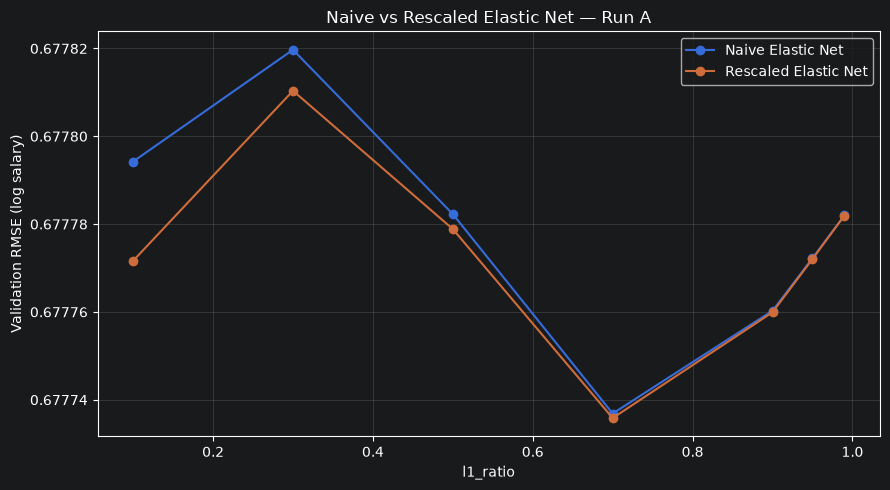

In [123]:
# ============================================================
# PHASE 7d — NAIVE VS RESCALED CHART
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

curve = pd.DataFrame(
    {
        "Naive Elastic Net": [
            best[f"naive_r{ratio}"][0]
            for ratio in L1_RATIOS
        ],
        "Rescaled Elastic Net": [
            best[f"resc_r{ratio}"][0]
            for ratio in L1_RATIOS
        ]
    },
    index=pd.Index(L1_RATIOS, name="l1_ratio")
)

print("=== NAIVE VS RESCALED ELASTIC NET ===")
display(curve.round(5))

ax = curve.plot(
    marker="o",
    figsize=(9, 5),
    title=f"Naive vs Rescaled Elastic Net — Run {RUN}"
)

ax.set_xlabel("l1_ratio")
ax.set_ylabel("Validation RMSE (log salary)")
ax.grid(alpha=0.25)

plt.tight_layout()

Path("results").mkdir(exist_ok=True)

plt.savefig(
    f"results/naive_vs_rescaled_{RUN}.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()